In [19]:
import numpy as np
from scipy.linalg import cholesky, solve_triangular, svd
import matplotlib.pyplot as plt
import time
import pandas as pd

from sklearn.preprocessing import StandardScaler
from KRR_utils import *
from nystrom_functions import *

In [20]:
rng = np.random.default_rng(1)

df = pd.read_csv("../Data/train.csv")
X = df.iloc[:, :-1].to_numpy(dtype=float)
y = df.iloc[:, -1].to_numpy(dtype=float)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

n = 2000
ind = rng.choice(X_scaled.shape[0], size=n, replace=False)
X_now = X_scaled[ind]
y_now = y[ind]

gamma = 1/X_now.shape[1]

def rbf3(A, B):
    K = rbf(A, B, gamma=gamma)
    return K

K = make_kernel_matrix(X_now, rbf3)


kernel = linear
full krr mse = 1550.8609763643606
full krr runtime = 0.1846980000846088

l = 1
uniform mse = 52662596072379.02
uniform forward error = 0.6206551334266399
uniform runtime = 0.21638739993795753
gaussian mse = 332993376401026.75
gaussian forward error = 0.8401582189152312
gaussian runtime = 0.1994540998712182

l = 21
uniform mse = 79094911696.61778
uniform forward error = 0.08434012606187162
uniform runtime = 0.2703245999291539
gaussian mse = 170201324505.90558
gaussian forward error = 0.07015630105950599
gaussian runtime = 0.23007009993307292

l = 41
uniform mse = 748914924.9560753
uniform forward error = 0.015037437137094807
uniform runtime = 0.25808319984935224
gaussian mse = 275634425.48727983
gaussian forward error = 0.011803914354955897
gaussian runtime = 0.2032514000311494

l = 61
uniform mse = 9428800.336812114
uniform forward error = 0.002248035816112976
uniform runtime = 0.2370895000640303
gaussian mse = 11945711.461482983
gaussian forward error = 0.001721746685

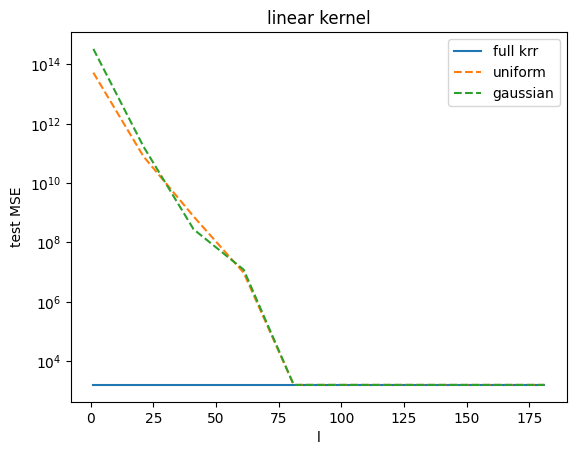

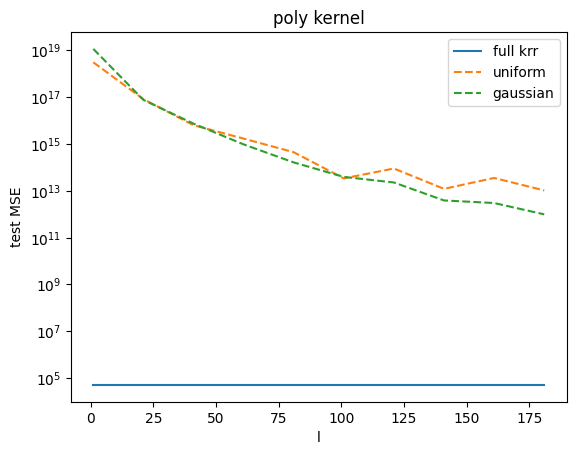

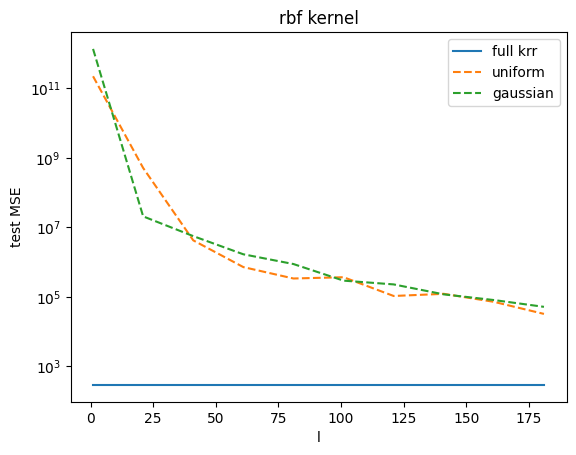

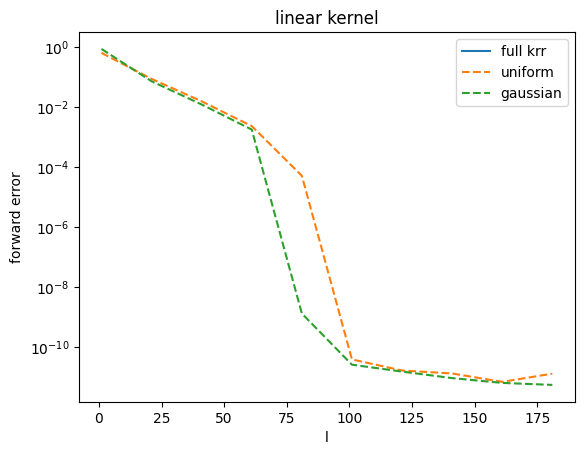

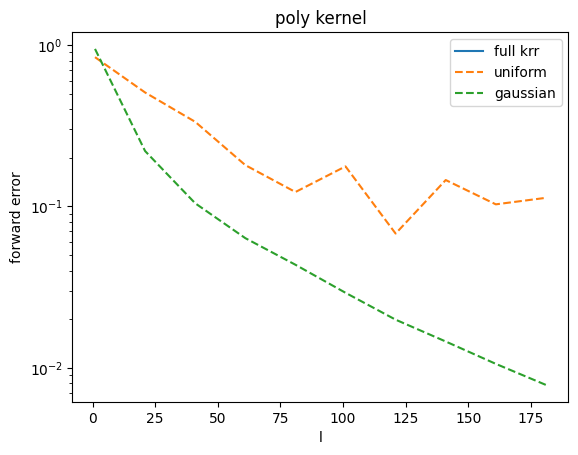

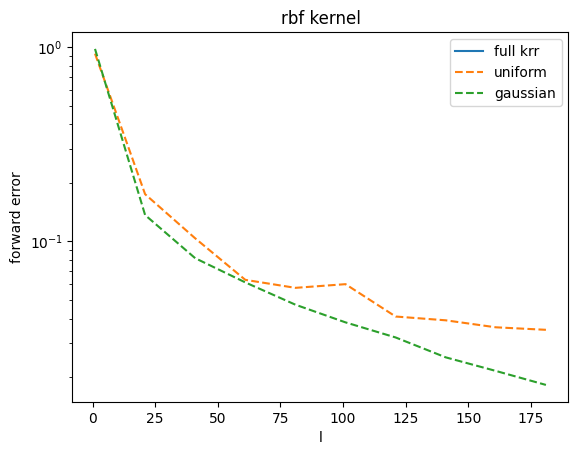

In [25]:
# real data version of the old fake data experiment

rng = np.random.default_rng(1)

df = pd.read_csv("../Data/train.csv")
X = df.iloc[:, :-1].to_numpy(dtype=float)
y = df.iloc[:, -1].to_numpy(dtype=float)

n_train = 800
n_test = 300
lam = 1e-2

ind = rng.choice(X.shape[0], size=n_train + n_test, replace=False)

train_ind = ind[:n_train]
test_ind = ind[n_train:]
X_train_raw = X[train_ind]
y_train = y[train_ind]
X_test_raw = X[test_ind]
y_test = y[test_ind]
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

gamma = 1/X_train.shape[1]

def rbf5(A, B):
    K = rbf(A, B, gamma=gamma)
    return K

def get_error(y_test, y_hat): #mse
    err = np.mean((y_test-y_hat)**2)
    return err

kernel_names = ["linear", "poly", "rbf"]
kernel_list = [linear, poly, rbf5]
l_values = range(1, 200, 20)
results = []

for a in range(len(kernel_list)):
    name = kernel_names[a]
    kernel = kernel_list[a]
    print("")
    print("kernel =", name)

    t0 = time.perf_counter()

    K_train = kernel(X_train, X_train)
    K_test = kernel(X_test, X_train)
    alpha = np.linalg.solve(K_train + lam*np.eye(n_train), y_train) #full krr
    y_hat = K_test @ alpha
    full_time = time.perf_counter() - t0
    full_mse = get_error(y_test, y_hat)

    print("full krr mse =", full_mse)
    print("full krr runtime =", full_time)

    for l in l_values:
        print("")
        print("l =", l)

        t0 = time.perf_counter()

        sample_ind = rng.choice(n_train, size=l, replace=False) #random uniform
        C = K_train[:, sample_ind]
        W = K_train[sample_ind, :]
        W = W[:, sample_ind]
        K_uni = C @ np.linalg.pinv(W) @ C.T
        alpha_uni = np.linalg.solve(K_uni + lam*np.eye(n_train), y_train)
        y_hat_uni = K_test @ alpha_uni

        uni_time = time.perf_counter() - t0

        uni_mse = get_error(y_test, y_hat_uni)
        uni_fro = np.linalg.norm(K_train-K_uni, ord="fro")/np.linalg.norm(K_train, ord="fro")

        print("uniform mse =", uni_mse)
        print("uniform forward error =", uni_fro)
        print("uniform runtime =", uni_time)

        t0 = time.perf_counter()

        U, eigs, K_gauss = random_nystrom(K_train, l, l, rng) #gaussian method
        alpha_gauss = np.linalg.solve(K_gauss + lam*np.eye(n_train), y_train)
        y_hat_gauss = K_test @ alpha_gauss

        gauss_time = time.perf_counter() - t0

        gauss_mse = get_error(y_test, y_hat_gauss)
        gauss_fro = np.linalg.norm(K_train-K_gauss, ord="fro")/np.linalg.norm(K_train, ord="fro")

        print("gaussian mse =", gauss_mse)
        print("gaussian forward error =", gauss_fro)
        print("gaussian runtime =", gauss_time)

        results.append([name, l, "full", full_mse, 0.0, full_time])
        results.append([name, l, "uniform", uni_mse, uni_fro, uni_time])
        results.append([name, l, "gaussian", gauss_mse, gauss_fro, gauss_time])

print("")
print("results")
print("kernel, l, method, mse, forward error, time")
for row in results:
    print(row)

for name in kernel_names:
    l_plot = []
    full_plot = []
    uni_plot = []
    gauss_plot = []

    for row in results:
        if row[0] == name and row[2] == "full":
            l_plot.append(row[1])
            full_plot.append(row[3])
        if row[0] == name and row[2] == "uniform":
            #l_plot.append(row[1])
            uni_plot.append(row[3])
        if row[0] == name and row[2] == "gaussian":
            gauss_plot.append(row[3])

    plt.figure()
    plt.semilogy(l_plot,full_plot,label="full krr")
    plt.semilogy(l_plot,uni_plot,'--',label="uniform")
    plt.semilogy(l_plot,gauss_plot,'--',label="gaussian")
    plt.xlabel("l")
    plt.ylabel("test MSE")
    plt.title(name + " kernel")
    plt.legend()
    plt.show()

for name in kernel_names:

    l_plot = []
    full_plot = []
    uni_plot = []
    gauss_plot = []

    for row in results:
        if row[0] == name and row[2] == "full":
            l_plot.append(row[1])
            full_plot.append(row[4])
        if row[0] == name and row[2] == "uniform":
            #l_plot.append(row[1])
            uni_plot.append(row[4])
        if row[0] == name and row[2] == "gaussian":
            gauss_plot.append(row[4])

    plt.figure()
    plt.semilogy(l_plot,full_plot, label="full krr")
    plt.semilogy(l_plot,uni_plot, '--', label="uniform")
    plt.semilogy(l_plot,gauss_plot,'--',label="gaussian")
    plt.xlabel("l")
    plt.ylabel("forward error")
    plt.title(name + " kernel")
    plt.legend()
    plt.show()

Okay, next we look at ...


l = 50
uniform forward error = 0.07663679137386464
gaussian forward error = 0.06920883246347877

l = 100
uniform forward error = 0.04262120907217884
gaussian forward error = 0.041822858946840194

l = 200
uniform forward error = 0.03144836568111781
gaussian forward error = 0.01991812481505648

l = 400
uniform forward error = 0.01677929523068097
gaussian forward error = 0.007271812847044613

l = 800
uniform forward error = 0.01023308201978765
gaussian forward error = 0.0011417355747993555


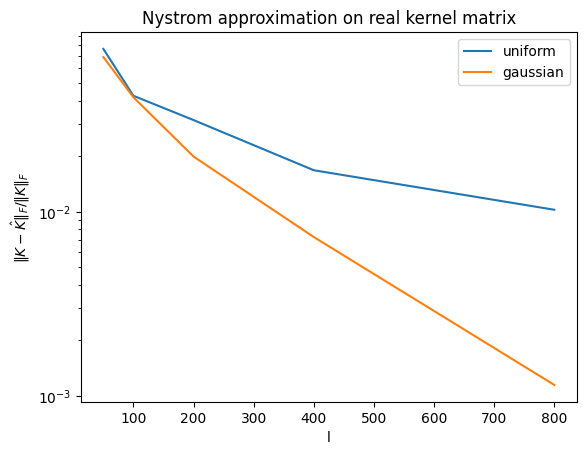

In [21]:
# Uniform column sampling vs randomized Nystrom on real data

l_values = [50, 100, 200, 400, 800]
l_plot = []
uni_plot = []
gauss_plot = []

for l in l_values:

    sample_ind = rng.choice(n, size=l, replace=False)
    K_uni = nystrom_CWCT(K, sample_ind)

    U, lam_gauss, K_gauss = random_nystrom(K, l, l, rng)

    uni_err = np.linalg.norm(K - K_uni, ord="fro") / np.linalg.norm(K, ord="fro")
    gauss_err = np.linalg.norm(K - K_gauss, ord="fro") / np.linalg.norm(K, ord="fro")

    print("")
    print("l =", l)
    print("uniform forward error =", uni_err)
    print("gaussian forward error =", gauss_err)

    l_plot.append(l)
    uni_plot.append(uni_err)
    gauss_plot.append(gauss_err)

plt.figure()
plt.semilogy(l_plot, uni_plot, label="uniform")
plt.semilogy(l_plot, gauss_plot, label="gaussian")
plt.xlabel("l")
plt.ylabel("$\|K-\hat K\|_F/\|K\|_F$")
plt.title("Nystrom approximation on real kernel matrix")
plt.legend()
plt.show()

In [22]:
r = 50
l_values = [100, 200, 400, 800]
rows = []

for l in l_values:
    # uniform
    uni_ind = uniform_sampling(n, l, rng)
    K_uni = nystrom_CWCT(K, uni_ind)
    err_uni = np.linalg.norm(K - K_uni, ord="fro") / np.linalg.norm(K, ord="fro")
    rows.append([l, "uniform", err_uni])

    # full leverage
    full_ind, full_scores = full_leverage(K, r, l, rng)
    K_full = nystrom_CWCT(K, full_ind)
    err_full = np.linalg.norm(K - K_full, ord="fro") / np.linalg.norm(K, ord="fro")
    rows.append([l, "full leverage", err_full])

    # approximate leverage, first 5 uniformly, then from approximate scores
    ini_l = 100
    extra_l = l - ini_l
    app_ind, app_scores, ini_ind = approximate_leverage(K, ini_l, extra_l, rng)
    K_app = nystrom_CWCT(K, app_ind)
    err_app = np.linalg.norm(K - K_app, ord="fro") / np.linalg.norm(K, ord="fro")
    rows.append([len(app_ind), "approx leverage", err_app])

df = pd.DataFrame(rows, columns=["l", "method", "relative_forward_error"])
df.to_csv("../Results/nystrom_sampling_error.csv", index=False)
df

,l,method,relative_forward_error
0,100,uniform,0.047681
1,100,full leverage,0.041380
2,100,approx leverage,0.047659
3,200,uniform,0.031639
4,200,full leverage,0.021724
5,200,approx leverage,0.030352
6,400,uniform,0.018788
7,400,full leverage,0.012150
8,400,approx leverage,0.019567
9,800,uniform,0.008142
